# Exploration des données DVF — 5 départements, 2021-2025

Objectif du notebook : comprendre la structure réelle des fichiers DVF géolocalisés avant de
les nettoyer, justifier chaque règle de nettoyage, puis explorer les prix et les volumes.

* **Source** : Demandes de valeurs foncières géolocalisées (Etalab, à partir des données DGFiP),
  un fichier CSV compressé par année et par département.
* **Périmètre** : Haute-Garonne (31), Gironde (33), Hérault (34), Loire-Atlantique (44), Rhône (69).
* **Prérequis** : `python run.py download clean analyze` (les fichiers bruts et le Parquet nettoyé
  sont lus depuis `data/`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from src import analyze as az
from src.clean import RAW_DTYPES, load_raw
from src.settings import load_config

az.ensure_browser()
pio.renderers.default = "png"        # images statiques : lisibles directement sur GitHub
pio.renderers["png"].width = 1000
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}".replace(",", " "))
cfg = load_config()
RAW = ROOT / "data" / "raw"


def fr(n: float, decimals: int = 0) -> str:
    # French number format: space as thousands separator, decimal comma
    return f"{n:,.{decimals}f}".replace(",", " ").replace(".", ",")

## 1. Les fichiers bruts

Un fichier par année et par département. On charge d'abord un seul fichier pour regarder le schéma.

In [2]:
files = sorted(RAW.glob("dvf_*.csv.gz"))
print(f"{len(files)} fichiers, {fr(sum(f.stat().st_size for f in files) / 1e6)} Mo compressés")
sample = pd.read_csv(RAW / "dvf_2025_69.csv.gz", dtype=str, nrows=200_000)
print(f"{sample.shape[1]} colonnes")
sample.head(3).T

25 fichiers, 59 Mo compressés


40 colonnes


,0,1,2
id_mutation,2025-858859,2025-858859,2025-858859
date_mutation,2025-01-03,2025-01-03,2025-01-03
numero_disposition,000001,000001,000001
nature_mutation,Vente,Vente,Vente
valeur_fonciere,225000,225000,225000
adresse_numero,86,86,86
adresse_suffixe,NaN,NaN,NaN
adresse_nom_voie,RUE DES COLLONGES,RUE DES COLLONGES,RUE DES COLLONGES
adresse_code_voie,0290,0290,0290
code_postal,69230,69230,69230


In [3]:
raw = load_raw(files)
print(f"{fr(len(raw))} lignes, {fr(raw['id_mutation'].nunique())} mutations")
raw.groupby(raw["date_mutation"].dt.year).agg(
    lignes=("id_mutation", "size"),
    mutations=("id_mutation", "nunique"),
    premiere_date=("date_mutation", "min"),
    derniere_date=("date_mutation", "max"),
)

2 248 608 lignes, 881 146 mutations


,lignes,mutations,premiere_date,derniere_date
date_mutation,,,,
2021,524944,214285,2021-01-02,2021-12-31
2022,522811,207796,2022-01-03,2022-12-31
2023,409982,159487,2023-01-02,2023-12-31
2024,368735,142696,2024-01-02,2024-12-31
2025,422136,156882,2025-01-02,2025-12-31


Les 5 années sont complètes (janvier à décembre). Les deux variables catégorielles qui pilotent le
nettoyage :

In [4]:
pd.concat(
    [
        raw["nature_mutation"].value_counts().rename("lignes").to_frame().assign(variable="nature_mutation"),
        raw["type_local"].value_counts(dropna=False).rename("lignes").to_frame().assign(variable="type_local"),
    ]
)

,lignes,variable
Vente,2028251,nature_mutation
Vente en l'état futur d'achèvement,191027,nature_mutation
Echange,17732,nature_mutation
Vente terrain à bâtir,6471,nature_mutation
Adjudication,4355,nature_mutation
Expropriation,772,nature_mutation
<NA>,786412,type_local
Dépendance,653197,type_local
Appartement,383505,type_local
Maison,343407,type_local


* Seules les **ventes** classiques nous intéressent : les ventes en l'état futur d'achèvement (VEFA,
  logements neufs vendus sur plan), les échanges, adjudications et expropriations ont des logiques
  de prix différentes.
* Une ligne sans `type_local` correspond à une parcelle de terrain sans local.

## 2. Le piège des mutations multi-lots

Une vente (`id_mutation`) occupe plusieurs lignes : le logement, la cave, le parking, le terrain…
La `valeur_fonciere` est **le prix total de la vente, répété sur chaque ligne**.

In [5]:
cols = ["id_mutation", "valeur_fonciere", "id_parcelle", "lot1_numero", "type_local",
        "surface_reelle_bati", "nombre_pieces_principales", "code_nature_culture", "surface_terrain"]
sales = raw[raw["nature_mutation"] == "Vente"]
print("Valeurs foncières distinctes par mutation :",
      sales.groupby("id_mutation")["valeur_fonciere"].nunique().max())
sales.loc[sales["id_mutation"] == "2024-333884", cols]

Valeurs foncières distinctes par mutation : 1


,id_mutation,valeur_fonciere,id_parcelle,lot1_numero,type_local,surface_reelle_bati,nombre_pieces_principales,code_nature_culture,surface_terrain
1457740,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,BT,7 900.0
1457741,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,BT,7 900.0
1457742,2024-333884,230 000.0,31563000AP0002,<NA>,Maison,99.0,5.0,S,2 540.0
1457743,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,S,2 540.0
1457744,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,S,2 540.0
1457745,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,S,2 540.0
1457746,2024-333884,230 000.0,31563000AP0002,<NA>,Dépendance,NaN,0.0,BT,7 900.0
1457747,2024-333884,230 000.0,31563000AP0002,<NA>,Maison,99.0,5.0,BT,7 900.0


Cette maison de 99 m² (vendue 230 000 €) apparaît **sur deux lignes**, une par nature de culture
de sa parcelle (« sols » et « taillis »), avec 6 lignes de dépendances. Deux conséquences :

1. additionner `valeur_fonciere` multiplierait le prix ;
2. compter les lignes « Maison » ferait croire à deux logements.

Ampleur de l'erreur si l'on sommait naïvement les prix :

In [6]:
dwell = sales[sales["type_local"].isin(["Maison", "Appartement"])]
naive_total = dwell["valeur_fonciere"].sum()
true_total = dwell.drop_duplicates("id_mutation")["valeur_fonciere"].sum()
print(f"Somme naïve sur les lignes logement : {fr(naive_total / 1e9, 1)} Md€")
print(f"Somme correcte (1 prix par vente)   : {fr(true_total / 1e9, 1)} Md€")
print(f"Surestimation : x{fr(naive_total / true_total, 2)}")

Somme naïve sur les lignes logement : 374,3 Md€
Somme correcte (1 prix par vente)   : 164,1 Md€
Surestimation : x2,28


In [7]:
key = ["id_mutation", "id_parcelle", "lot1_numero", "type_local",
       "surface_reelle_bati", "nombre_pieces_principales"]
lignes = dwell.groupby("id_mutation").size()
distincts = dwell.drop_duplicates(key).groupby("id_mutation").size()
pd.DataFrame({
    "comptage par lignes": lignes.clip(upper=4).value_counts().sort_index(),
    "comptage par logement distinct": distincts.clip(upper=4).value_counts().sort_index(),
}).rename(index={4: "4 et +"}).rename_axis("logements par mutation")

,comptage par lignes,comptage par logement distinct
logements par mutation,,
1,515212,554864
2,52014,18247
3,6246,3741
4 et +,7321,3941


Compter les **logements distincts** (parcelle, lot, type, surface, pièces) plutôt que les lignes
évite d'exclure à tort des dizaines de milliers de ventes d'un seul logement.

## 3. Entonnoir de nettoyage

Le détail des règles est dans `src/clean.py` et `docs/methodology.md`.

In [8]:
report = pd.read_csv(ROOT / "reports" / "tables" / "cleaning_report.csv")
report

,step,description,rows_before,rows_after,mutations_before,mutations_after
0,1_vente,nature_mutation = 'Vente',2248608,2028251,881146,795101
1,2_logement,Mutation contenant une Maison ou un Appartement,2028251,1510649,795101,580793
2,3_un_logement,"1 ligne par mutation, un seul logement",1510649,547030,580793,547030
3,4_valeurs_manquantes,Prix et surface renseignés et > 0,547030,546778,547030,546778
4,6a_bornes,Bornes dures surface et prix,546778,545182,546778,545182
5,6b_percentiles,prix_m2 entre P1 et P99 (dép. x type),545182,534309,545182,534309


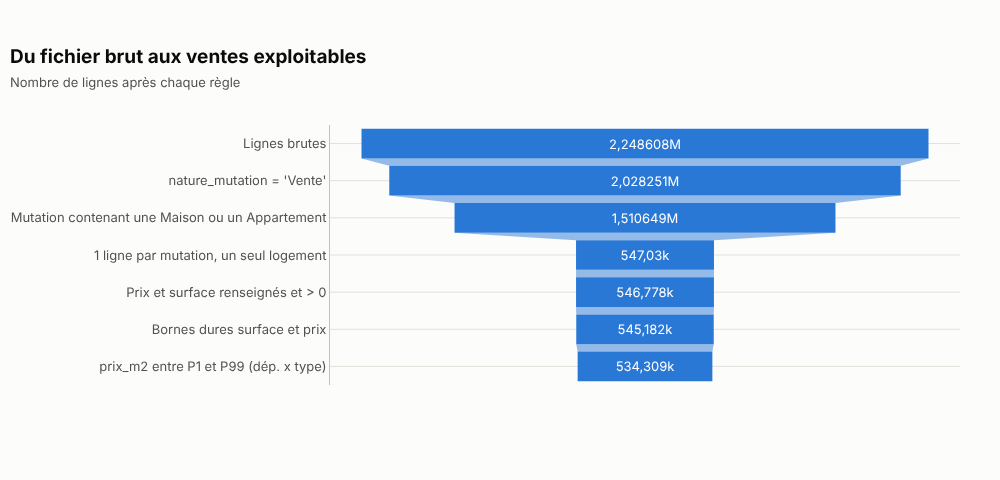

In [9]:
fig = go.Figure(go.Funnel(
    y=["Lignes brutes"] + report["description"].tolist(),
    x=[report.loc[0, "rows_before"]] + report["rows_after"].tolist(),
    marker={"color": az.SEQ_MID}, textinfo="value",
))
az.base_layout(fig, "Du fichier brut aux ventes exploitables", "Nombre de lignes après chaque règle", height=480)
fig.update_layout(margin={"l": 330})
fig.show()

## 4. Données nettoyées

In [10]:
df = pd.read_parquet(ROOT / "data" / "processed" / "ventes_clean.parquet")
print(f"{fr(len(df))} ventes, {fr(df['code_commune'].nunique())} communes")
df[["valeur_fonciere", "surface_reelle_bati", "prix_m2", "nombre_pieces_principales", "surface_terrain"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

534 309 ventes, 1 939 communes


,count,mean,std,min,1%,25%,50%,75%,99%,max
valeur_fonciere,534 309.0,264 208.8,187 098.1,10 000.0,48 000.0,145 000.0,220 000.0,330 000.0,945 000.0,5 100 000.0
surface_reelle_bati,534 309.0,79.3,41.5,9.0,18.0,50.0,73.0,99.0,213.0,1 000.0
prix_m2,534 309.0,3 454.6,1 485.7,416.7,775.0,2 441.9,3 289.5,4 264.9,7 901.4,14 036.8
nombre_pieces_principales,534 309.0,3.4,1.5,0.0,1.0,2.0,3.0,4.0,7.0,54.0
surface_terrain,534 309.0,781.2,7 867.6,0.0,0.0,0.0,0.0,513.0,8 891.8,1 822 916.0


In [11]:
df.isna().mean().mul(100).round(2).loc[lambda s: s > 0].rename("% manquant").to_frame()

,% manquant
longitude,1.5
latitude,1.5
ville_principale,63.0


Seules les coordonnées manquent parfois (parcelles non géocodées) : sans effet sur les prix, ces
ventes sont simplement absentes de la carte.

### Distribution du prix au m²

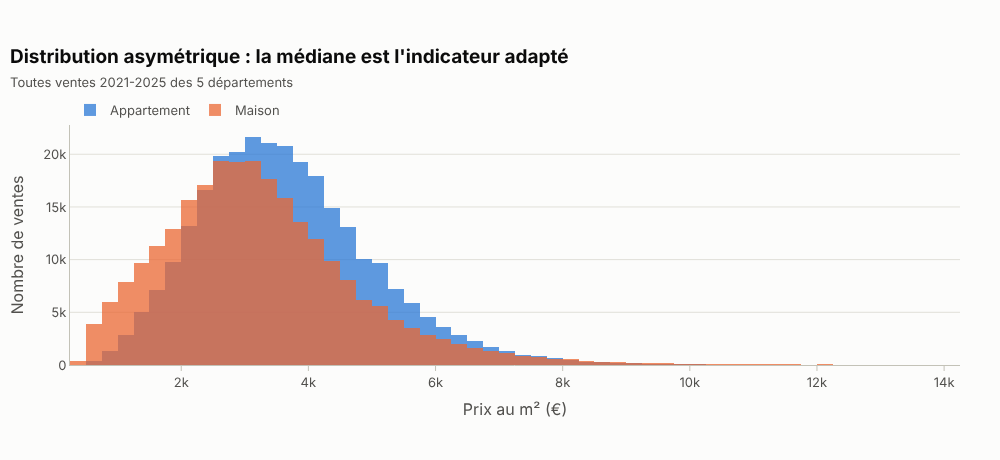

In [12]:
fig = go.Figure()
for typ, color in (("Appartement", az.CATEGORICAL[0]), ("Maison", az.CATEGORICAL[1])):
    fig.add_trace(go.Histogram(x=df.loc[df["type_local"] == typ, "prix_m2"], name=typ,
                               marker_color=color, opacity=0.75, xbins={"size": 250}))
fig.update_layout(barmode="overlay")
fig.update_xaxes(title="Prix au m² (€)")
fig.update_yaxes(title="Nombre de ventes")
az.base_layout(fig, "Distribution asymétrique : la médiane est l'indicateur adapté",
               "Toutes ventes 2021-2025 des 5 départements", height=460)
fig.show()

In [13]:
(df.groupby("type_local")["prix_m2"].agg(["mean", "median"])
   .assign(ecart_moyenne_mediane_pct=lambda t: (t["mean"] / t["median"] - 1) * 100))

,mean,median,ecart_moyenne_mediane_pct
type_local,,,
Appartement,3 641.7,3 500.0,4.0
Maison,3 250.7,3 054.2,6.4


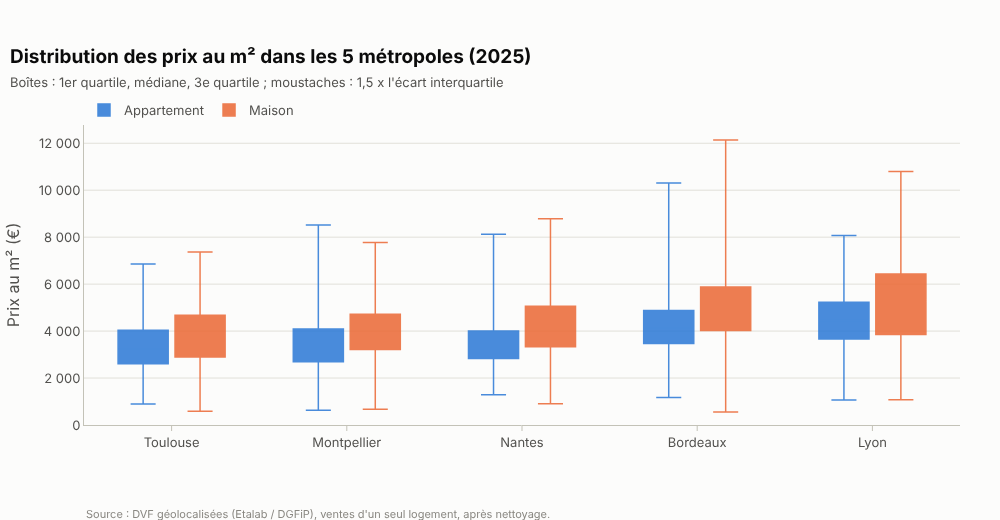

In [14]:
last = int(df["annee"].max())
az.fig_distribution(df, cfg["metropoles"], last).show()

## 5. Prix et volumes dans le temps

In [15]:
yearly_all = df.groupby("annee").agg(nb_ventes=("prix_m2", "size"), prix_m2_median=("prix_m2", "median"))
yearly_all["evol_volume_pct"] = yearly_all["nb_ventes"].pct_change() * 100
yearly_all["evol_prix_pct"] = yearly_all["prix_m2_median"].pct_change() * 100
yearly_all

,nb_ventes,prix_m2_median,evol_volume_pct,evol_prix_pct
annee,,,,
2021,128360,3 214.3,NaN,NaN
2022,123007,3 423.1,-4.2,6.5
2023,96004,3 383.0,-22.0,-1.2
2024,85678,3 214.7,-10.8,-5.0
2025,101260,3 210.7,18.2,-0.1


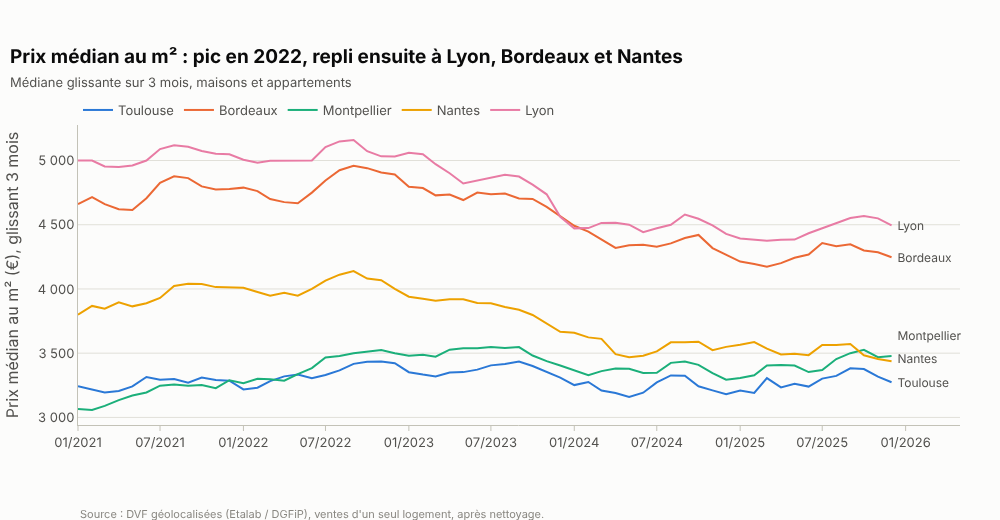

In [16]:
monthly = az.city_monthly(df)
az.fig_monthly_price(monthly, cfg["metropoles"]).show()

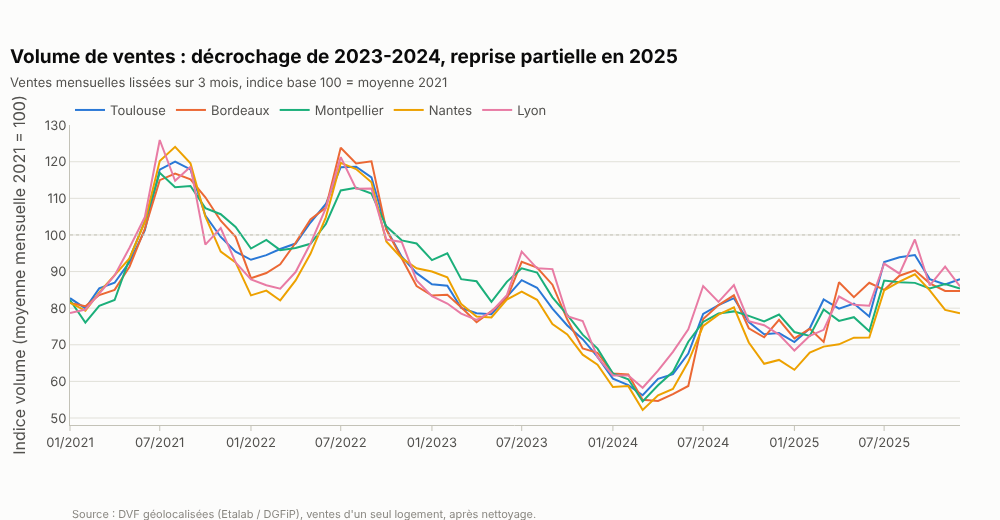

In [17]:
az.fig_monthly_volume(monthly, cfg["metropoles"], int(df["annee"].min())).show()

## 6. Effet de la hausse des taux

On compare 2021 (taux bas) à 2023 (taux au plus haut) : variation du nombre de ventes et du prix
médian au m², ville par ville.

In [18]:
yearly = az.city_yearly(df)
effect = az.rate_rise_effect(yearly, 2021, 2023, last)
effect[["ville_principale", "evol_volume_hausse_taux_pct", "evol_prix_hausse_taux_pct",
        "evol_volume_total_pct", "evol_prix_total_pct"]]

,ville_principale,evol_volume_hausse_taux_pct,evol_prix_hausse_taux_pct,evol_volume_total_pct,evol_prix_total_pct
0,Vénissieux,-31.8,7.8,-26.7,-2.6
1,Pessac,-31.3,2.9,-20.7,-6.4
2,Villeurbanne,-30.5,-1.4,-31.5,-8.3
3,Tournefeuille,-24.3,9.4,-16.6,1.5
4,Nantes,-24.1,-2.7,-22.7,-11.5
5,Toulouse,-22.6,3.0,-14.4,1.1
6,Sète,-21.6,14.3,-24.8,18.8
7,Bordeaux,-20.7,-1.2,-16.8,-10.2
8,Lyon,-20.2,-3.9,-15.1,-11.1
9,Saint-Herblain,-19.4,2.2,-21.3,-3.9


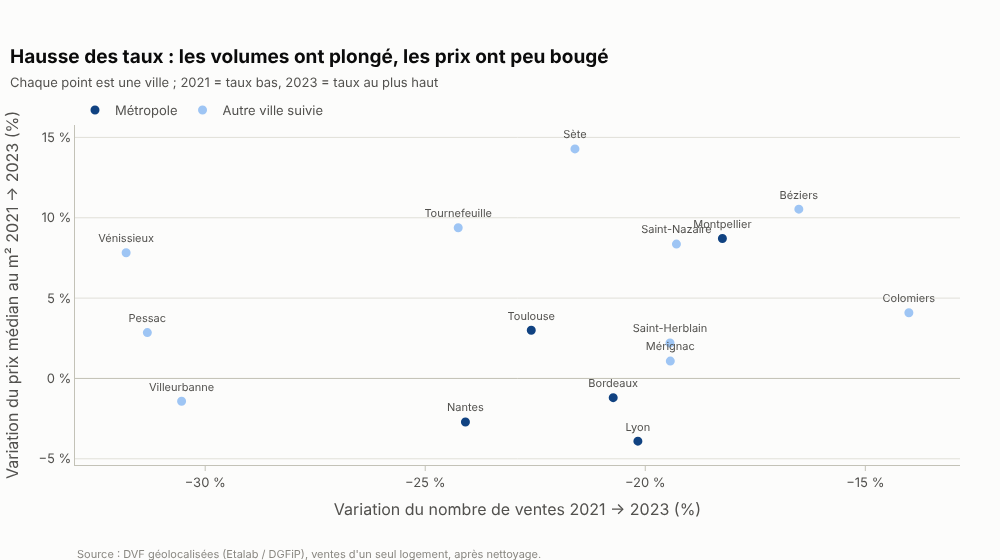

In [19]:
az.fig_rate_effect(effect, 2021, 2023, cfg["metropoles"]).show()

## 7. Test statistique : les prix 2025 diffèrent-ils de 2021 ?

Test de Mann-Whitney U (non paramétrique, adapté à des distributions asymétriques), par ville,
avec correction de Bonferroni pour le nombre de tests. La taille d'effet est la corrélation
rang-bisérielle *r* (> 0 : prix plus élevés en 2025).

In [20]:
tests = az.price_tests(df, 2021, last, cfg["analysis"]["alpha"], cfg["analysis"]["min_sales_for_test"])
tests.loc[tests["type_local"] == "Ensemble",
          ["ville_principale", "mediane_2021", f"mediane_{last}", "evol_mediane_pct",
           "p_value", "significatif", "r_rang_biseriel", "taille_effet"]]

,ville_principale,mediane_2021,mediane_2025,evol_mediane_pct,p_value,significatif,r_rang_biseriel,taille_effet
1,Bordeaux,4 752.1,4 269.2,-10.2,0.0,True,-0.2,faible
4,Béziers,1 687.1,1 913.0,13.4,0.0,True,0.2,faible
7,Colomiers,2 695.4,2 774.4,2.9,0.2,False,0.0,négligeable
10,Lyon,5 027.0,4 468.1,-11.1,0.0,True,-0.2,faible
13,Montpellier,3 209.9,3 432.8,6.9,0.0,True,0.1,faible
16,Mérignac,3 829.0,3 597.0,-6.1,0.0,True,-0.2,faible
19,Nantes,3 952.6,3 500.0,-11.5,0.0,True,-0.2,faible
22,Pessac,3 930.3,3 676.9,-6.4,0.0,True,-0.1,faible
25,Saint-Herblain,2 973.0,2 857.7,-3.9,0.0,True,-0.1,faible
28,Saint-Nazaire,2 768.5,2 857.1,3.2,0.0,False,0.1,négligeable


In [21]:
for text in tests.loc[tests["type_local"] == "Ensemble", "interpretation"]:
    print("-", text)

- Bordeaux : prix au m² plus bas en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 40 % de chances d'être plus chère au m² qu'une vente 2021.
- Béziers : prix au m² plus élevés en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 59 % de chances d'être plus chère au m² qu'une vente 2021.
- Colomiers : pas de différence statistiquement significative entre 2021 et 2025 (p = 0,194, seuil corrigé 0,0011).
- Lyon : prix au m² plus bas en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 38 % de chances d'être plus chère au m² qu'une vente 2021.
- Montpellier : prix au m² plus élevés en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 55 % de chances d'être plus chère au m² qu'une vente 2021.
- Mérignac : prix au m² plus bas en 2025 qu'en 2021 (p < 0,001 ; effet faible). Une vente 2025 prise au hasard a 42 % de chances d'être plus chère au m² qu'une vente 2021.
- Nantes : prix au m

Avec plusieurs milliers de ventes par ville, de petits écarts deviennent significatifs : la
**taille d'effet** (faible partout) rappelle que la baisse, réelle, reste modérée à l'échelle
d'une transaction individuelle.

## 8. Accessibilité

In [22]:
afford = az.affordability(yearly, cfg["analysis"]["budgets"], last)
(afford[afford["type_local"] == "Appartement"]
   .pivot(index="ville_principale", columns="budget", values="m2_achetables")
   .sort_values(150000, ascending=False)
   .round(0))

budget,150000,250000,350000
ville_principale,,,
Béziers,88.0,147.0,206.0
Vénissieux,59.0,98.0,138.0
Saint-Herblain,58.0,97.0,136.0
Colomiers,56.0,93.0,131.0
Saint-Nazaire,53.0,88.0,123.0
Tournefeuille,51.0,85.0,119.0
Toulouse,46.0,77.0,108.0
Nantes,44.0,74.0,103.0
Montpellier,44.0,74.0,103.0


In [23]:
ratio = az.income_ratio(yearly, cfg, last)
ratio

,ville_principale,prix_median,revenu_menage_median,annees_de_revenu
0,Béziers,117 700.0,24 561.0,4.8
1,Colomiers,184 000.0,36 144.0,5.1
2,Saint-Herblain,185 000.0,34 378.0,5.4
3,Tournefeuille,251 950.0,45 609.0,5.5
4,Nantes,190 100.0,34 227.0,5.6
5,Toulouse,171 500.0,30 746.0,5.6
6,Vénissieux,167 000.0,27 974.0,6.0
7,Montpellier,165 000.0,27 611.0,6.0
8,Mérignac,217 000.0,36 294.0,6.0
9,Saint-Nazaire,190 000.0,31 398.0,6.1


## 9. À retenir

* Les fichiers DVF ne sont pas « une ligne = une vente » : la déduplication par mutation et le
  comptage des logements distincts sont indispensables.
* Le marché s'est ajusté **par les volumes** (-25 % de ventes entre 2021 et 2023 sur le périmètre)
  bien plus que par les prix.
* Les métropoles les plus chères (Lyon, Bordeaux, Nantes) reculent nettement en euros courants ;
  le littoral héraultais (Sète, Béziers) et Montpellier progressent.

Les constats chiffrés complets sont dans `reports/findings.md`.